In [0]:
%sql
CREATE DATABASE BIG_DATA

ok


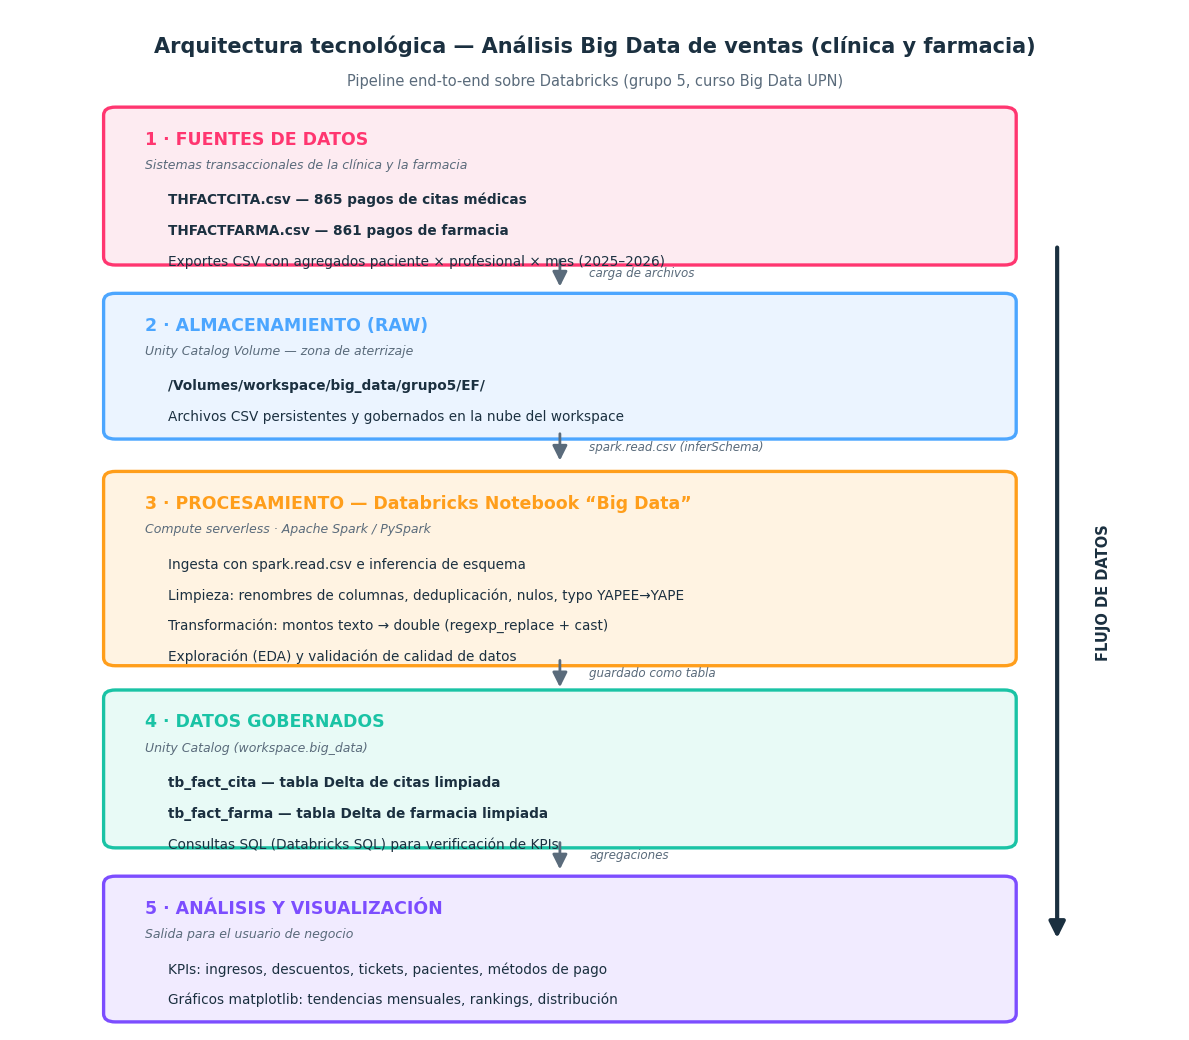

In [0]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(12, 10.5))
ax.set_xlim(0, 10); ax.set_ylim(0, 12.6); ax.axis('off')

# Título general
ax.text(5, 12.15, "Arquitectura tecnológica — Análisis Big Data de ventas (clínica y farmacia)",
        ha='center', va='center', fontsize=15, fontweight='bold', color='#1B3040')
ax.text(5, 11.72, "Pipeline end-to-end sobre Databricks (grupo 5, curso Big Data UPN)",
        ha='center', va='center', fontsize=10.5, color='#5A6B7B')

def capa(y, alto, titulo, subtitulo, lineas, color, face):
    ax.add_patch(FancyBboxPatch((0.9, y), 7.6, alto, boxstyle="round,pad=0.10",
                                linewidth=2.4, edgecolor=color, facecolor=face))
    ax.text(1.15, y + alto - 0.30, titulo, ha='left', va='center',
            fontsize=12.5, fontweight='bold', color=color)
    ax.text(1.15, y + alto - 0.62, subtitulo, ha='left', va='center',
            fontsize=9, style='italic', color='#5A6B7B')
    for i, (txt, bold) in enumerate(lineas):
        ax.text(1.35, y + alto - 1.05 - i*0.38, txt, ha='left', va='center',
                fontsize=9.8, fontweight=('bold' if bold else 'normal'), color='#1B3040')

def flecha(y1, y2, etiqueta):
    ax.add_patch(FancyArrowPatch((4.7, y1), (4.7, y2), arrowstyle='-|>',
                                 mutation_scale=22, linewidth=2, color='#5A6B7B'))
    ax.text(4.95, (y1+y2)/2, etiqueta, ha='left', va='center', fontsize=8.6, color='#5A6B7B', style='italic')

# --- Capas (de arriba a abajo) ---
capa(9.55, 1.75, "1 · FUENTES DE DATOS", "Sistemas transaccionales de la clínica y la farmacia",
     [("THFACTCITA.csv — 865 pagos de citas médicas", True),
      ("THFACTFARMA.csv — 861 pagos de farmacia", True),
      ("Exportes CSV con agregados paciente × profesional × mes (2025–2026)", False)],
     '#FF3670', '#FDEBF1')

flecha(9.55, 9.15, "carga de archivos")

capa(7.40, 1.60, "2 · ALMACENAMIENTO (RAW)", "Unity Catalog Volume — zona de aterrizaje",
     [("/Volumes/workspace/big_data/grupo5/EF/", True),
      ("Archivos CSV persistentes y gobernados en la nube del workspace", False)],
     '#4CA6FF', '#EBF4FF')

flecha(7.40, 7.00, "spark.read.csv (inferSchema)")

capa(4.60, 2.20, "3 · PROCESAMIENTO — Databricks Notebook \u201cBig Data\u201d", "Compute serverless · Apache Spark / PySpark",
     [("Ingesta con spark.read.csv e inferencia de esquema", False),
      ("Limpieza: renombres de columnas, deduplicación, nulos, typo YAPEE→YAPE", False),
      ("Transformación: montos texto → double (regexp_replace + cast)", False),
      ("Exploración (EDA) y validación de calidad de datos", False)],
     '#FF9E1B', '#FFF3E2')

flecha(4.60, 4.20, "guardado como tabla")

capa(2.35, 1.75, "4 · DATOS GOBERNADOS", "Unity Catalog (workspace.big_data)",
     [("tb_fact_cita — tabla Delta de citas limpiada", True),
      ("tb_fact_farma — tabla Delta de farmacia limpiada", True),
      ("Consultas SQL (Databricks SQL) para verificación de KPIs", False)],
     '#1AC3A5', '#E8FAF6')

flecha(2.35, 1.95, "agregaciones")

capa(0.20, 1.60, "5 · ANÁLISIS Y VISUALIZACIÓN", "Salida para el usuario de negocio",
     [("KPIs: ingresos, descuentos, tickets, pacientes, métodos de pago", False),
      ("Gráficos matplotlib: tendencias mensuales, rankings, distribución", False)],
     '#7C4DFF', '#F1EBFF')

# Barra lateral del flujo
ax.add_patch(FancyArrowPatch((8.95, 9.7), (8.95, 1.1), arrowstyle='-|>',
                             mutation_scale=24, linewidth=3, color='#1B3040'))
ax.text(9.35, 5.4, "FLUJO DE DATOS", rotation=90, ha='center', va='center',
        fontsize=10.5, fontweight='bold', color='#1B3040')

plt.tight_layout()
plt.savefig("/tmp/arquitectura.png", dpi=110, bbox_inches='tight')
print("ok")

In [0]:
%fs ls /Volumes/workspace/big_data/grupo5/EF/THFACTCITA.csv

path,name,size,modificationTime
dbfs:/Volumes/workspace/big_data/grupo5/EF/THFACTCITA.csv,THFACTCITA.csv,61722,1795494281000


In [0]:
%fs head dbfs:/Volumes/workspace/big_data/grupo5/EF/THFACTCITA.csv

﻿IDPAGO,IDPACIENTE,IDMEDICO,Suma de TOTAL_CITAS,NOMBRE_SEGURO,METODO_PAGO,Año,Trimestre,Mes,Día,Suma de MONTO,Suma de DESCUENTO (%),Suma de PAGO_FINAL
P001,P01,M01,1,NINGUNO,YAPE,2025,Trim. 3,septiembre,15,S/ 50,0,S/ 50
P002,P02,M02,1,SIS,EFECTIVO,2025,Trim. 4,octubre,1,S/ 60,0,S/ 60
P003,P03,M03,1,ESSALUD,TARJETA,2025,Trim. 4,octubre,11,S/ 45,0,S/ 45
P004,P04,M04,1,EPS PACIFICO,YAPE,2025,Trim. 4,octubre,14,S/ 55,15,S/ 46.75
P005,P05,M05,1,EPS RIMAC,EFECTIVO,2025,Trim. 4,octubre,15,S/ 40,15,S/ 34
P006,P06,M06,1,EPS MAPFRE,YAPE,2025,Trim. 4,noviembre,10,S/ 70,20,S/ 56
P007,P07,M07,1,LA POSITIVA,TARJETA,2025,Trim. 4,noviembre,26,S/ 50,20,S/ 40
P008,P08,M08,1,ONCOSALUD,EFECTIVO,2025,Trim. 4,diciembre,6,S/ 55,20,S/ 44
P009,P09,M09,1,NINGUNO,YAPE,2025,Trim. 4,diciembre,15,S/ 60,0,S/ 60
P010,P10,M10,1,NINGUNO,TARJETA,2025,Trim. 4,diciembre,24,S/ 65,0,S/ 65
P011,P11,M11,1,ESSALUD,EFECTIVO,2026,Trim. 1,enero,12,S/ 55,0,S/ 55
P012,P12,M12,1,EPS RIMAC,YAPE,2026,Trim. 1,febrero,7,S/ 50,15,S/ 42.5

In [0]:
dfFactCita = spark.read.csv("/Volumes/workspace/big_data/grupo5/EF/THFACTCITA.csv",header=True,inferSchema=True)

In [0]:
dfFactCita=dfFactCita.withColumnRenamed("IDPAGO","ID_PAGO").withColumnRenamed("IDPACIENTE","ID_PACIENTE").withColumnRenamed("IDMEDICO","ID_MEDICO").withColumnRenamed("Suma de TOTAL_CITAS","Suma_TOTAL_CITAS").withColumnRenamed("Suma de MONTO","Suma_MONTO").withColumnRenamed("Suma de DESCUENTO (%)","Suma_DESCUENTO").withColumnRenamed("Suma de PAGO_FINAL","Suma_PAGO_FINAL")

In [0]:
limpio_df = dfFactCita.na.drop(subset=["ID_PACIENTE", "ID_MEDICO"]).dropDuplicates().filter("Suma_TOTAL_CITAS >= 1").replace("YAPEE", "YAPE", subset=["METODO_PAGO"]).na.fill({"NOMBRE_SEGURO": "NINGUNO", "Suma_DESCUENTO": 0})
display(limpio_df)

ID_PAGO,ID_PACIENTE,ID_MEDICO,Suma_TOTAL_CITAS,NOMBRE_SEGURO,METODO_PAGO,Año,Trimestre,Mes,Día,Suma_MONTO,Suma_DESCUENTO,Suma_PAGO_FINAL
P043,P18,M05,2,EPS MAPFRE,EFECTIVO,2026,Trim. 3,julio,4,S/ 55,20,S/ 44
P046,P67,M28,1,SIS,TARJETA,2026,Trim. 3,julio,8,S/ 70,0,S/ 70
P061,P83,M13,1,EPS PACIFICO,YAPE,2026,Trim. 3,julio,13,S/ 60,15,S/ 51
P075,P97,M11,1,SIS,PLIN,2026,Trim. 3,julio,15,S/ 60,0,S/ 60
P090,P112,M34,1,EPS PACIFICO,EFECTIVO,2026,Trim. 3,julio,17,S/ 55,15,S/ 46.75
P111,P133,M37,1,NINGUNO,YAPE,2026,Trim. 3,julio,20,S/ 45,0,S/ 45
P130,P153,M02,1,EPS PACIFICO,PLIN,2026,Trim. 3,julio,21,S/ 70,15,S/ 59.5
P144,P164,M01,1,ESSALUD,YAPE,2026,Trim. 3,julio,22,S/ 40,0,S/ 40
P148,P169,M16,1,NINGUNO,YAPE,2026,Trim. 3,julio,23,S/ 40,0,S/ 40
P177,P54,M07,1,ONCOSALUD,YAPE,2026,Trim. 3,julio,31,S/ 50,20,S/ 40


Databricks visualization. Run in Databricks to view.

Databricks visualization. Run in Databricks to view.

Databricks visualization. Run in Databricks to view.

Databricks visualization. Run in Databricks to view.

In [0]:
%fs ls /Volumes/workspace/big_data/grupo5/EF/THFACTFARMA.csv

path,name,size,modificationTime
dbfs:/Volumes/workspace/big_data/grupo5/EF/THFACTFARMA.csv,THFACTFARMA.csv,53319,1795494281000


In [0]:
%fs head dbfs:/Volumes/workspace/big_data/grupo5/EF/THFACTFARMA.csv

﻿IDPAGOFARMA,IDPACIENTE,IDFARMACEU,IDMEDICAMENTO,METODO_PAGO,Año,Trimestre,Mes,Día,Suma de PRECIO_UNIDAD,Suma de CANTIDAD,Suma de TOTAL_PAGO
PF005,P06,F009,MC001,YAPE,2025,Trim. 4,noviembre,10,2,10,27
PF012,P18,F002,MC001,TARJETA,2026,Trim. 2,mayo,31,2,10,32
PF014,P22,F005,MC001,TARJETA,2026,Trim. 2,junio,27,2,10,146
PF032,P67,F019,MC001,TARJETA,2026,Trim. 3,julio,15,2,14,28
PF035,P105,F014,MC001,TARJETA,2026,Trim. 3,julio,15,2,15,30
PF043,P117,F006,MC001,TARJETA,2026,Trim. 3,julio,16,2,14,28
PF050,P127,F008,MC001,TRANSFERENCIA,2026,Trim. 3,julio,17,2,20,40
PF053,P125,F027,MC001,YAPE,2026,Trim. 3,julio,18,2,12,68
PF088,P160,F005,MC001,TARJETA,2026,Trim. 3,julio,23,2,9,18
PF090,P118,F013,MC001,YAPE,2026,Trim. 3,julio,23,2,14,28
PF098,P93,F025,MC001,TARJETA,2026,Trim. 3,julio,24,2,15,30
PF101,P138,F026,MC001,TARJETA,2026,Trim. 3,julio,25,2,10,20
PF120,P180,F022,MC001,TARJETA,2026,Trim. 3,julio,29,2,20,40
PF122,P155,F013,MC001,EFECTIVO,2026,Trim. 3,julio,29,2,20,40
PF128,P206,F014,MC001,T

In [0]:
dfFactFarma = spark.read.csv("/Volumes/workspace/big_data/grupo5/EF/THFACTFARMA.csv", header=True, inferSchema=True)

In [0]:
dfFactFarma=dfFactFarma.withColumnRenamed("IDPAGOFARMA","ID_PAGO_FARMA").withColumnRenamed("IDPACIENTE","ID_PACIENTE").withColumnRenamed("IDFARMACEU","ID_FARMACEU").withColumnRenamed("IDMEDICAMENTO","ID_MEDICAMENTO").withColumnRenamed("Suma de PRECIO_UNIDAD","Suma_PRECIO_UNIDAD").withColumnRenamed("Suma de CANTIDAD","SUMA_CANTIDAD").withColumnRenamed("Suma de TOTAL_PAGO","Suma_TOTAL_PAGO")

In [0]:
limpio_df = dfFactFarma.na.drop().dropDuplicates().filter("`Suma de CANTIDAD` >= 1 AND `Suma de PRECIO_UNIDAD` > 0").drop("Suma de TOTAL_PAGO").selectExpr("*", "`Suma de PRECIO_UNIDAD` * `Suma de CANTIDAD` AS `Suma de TOTAL_PAGO`")
display(limpio_df)

IDPAGOFARMA,IDPACIENTE,IDFARMACEU,IDMEDICAMENTO,METODO_PAGO,Año,Trimestre,Mes,Día,Suma de PRECIO_UNIDAD,Suma de CANTIDAD,Suma de TOTAL_PAGO
PF090,P118,F013,MC001,YAPE,2026,Trim. 3,julio,23,2,14,28
PF204,P271,F012,MC001,TRANSFERENCIA,2026,Trim. 3,agosto,10,2,21,42
PF405,P458,F029,MC001,TARJETA,2026,Trim. 3,septiembre,12,2,9,18
PF586,P668,F022,MC001,YAPE,2026,Trim. 4,octubre,12,2,12,24
PF074,P97,F019,MC002,PLIN,2026,Trim. 3,julio,20,3,10,30
PF383,P452,F001,MC002,TARJETA,2026,Trim. 3,septiembre,8,3,10,30
PF513,P576,F023,MC002,YAPE,2026,Trim. 4,octubre,1,3,9,27
PF620,P689,F024,MC002,PLIN,2026,Trim. 4,octubre,19,3,6,18
PF670,P764,F001,MC002,PLIN,2026,Trim. 4,octubre,27,3,10,30
PF722,P814,F016,MC002,EFECTIVO,2026,Trim. 4,noviembre,2,3,21,63


Databricks visualization. Run in Databricks to view.

Databricks visualization. Run in Databricks to view.

Databricks visualization. Run in Databricks to view.

Databricks visualization. Run in Databricks to view.

In [0]:
dfFactFarma.write.saveAsTable("big_data.tb_fact_farma")

# Análisis de ventas — Farmacia (`dfFactFarma`)

Análisis exploratorio (EDA), indicadores clave (KPIs) y visualizaciones de las ventas de farmacia de la clínica, a partir de `big_data.tb_fact_farma`. Cada sección incluye una explicación de qué muestra y cómo interpretarla.

## 1. EDA — Exploración inicial

Revisamos primero la **estructura** del DataFrame: número de filas, columnas y tipos de datos. Conocer los tipos importa porque un monto guardado como texto (como pasaba en la tabla de citas con el prefijo "S/") obligaría a convertirlo antes de poder sumarlo.

In [0]:
print(f"Filas: {dfFactFarma.count()} | Columnas: {len(dfFactFarma.columns)}")
dfFactFarma.printSchema()

Filas: 861 | Columnas: 12
root
 |-- ID_PAGO_FARMA: string (nullable = true)
 |-- ID_PACIENTE: string (nullable = true)
 |-- ID_FARMACEU: string (nullable = true)
 |-- ID_MEDICAMENTO: string (nullable = true)
 |-- METODO_PAGO: string (nullable = true)
 |-- Año: integer (nullable = true)
 |-- Trimestre: string (nullable = true)
 |-- Mes: string (nullable = true)
 |-- Día: integer (nullable = true)
 |-- Suma_PRECIO_UNIDAD: integer (nullable = true)
 |-- SUMA_CANTIDAD: integer (nullable = true)
 |-- Suma_TOTAL_PAGO: integer (nullable = true)



**Qué vemos:** 861 filas y 12 columnas. Cada fila es **un pago de farmacia** (`ID_PAGO_FARMA` es único). Hay 5 identificadores (pago, paciente, farmacéutico, medicamento), el método de pago, un bloque de calendario (`Año`, `Trimestre`, `Mes`, `Día`) y 3 métricas numéricas ya tipadas como `int` — a diferencia de la tabla de citas, aquí los montos **no** traen el prefijo "S/ ", así que se pueden usar directamente.

### 1.1 Calidad de datos

Antes de calcular cualquier KPI validamos: nulos, filas con valores en cero, duplicados (mismo `ID_PAGO_FARMA` repetido) y consistencia aritmética (`TOTAL_PAGO` frente a `PRECIO_UNIDAD × CANTIDAD`).

In [0]:
chequeos = spark.sql("""
SELECT
  SUM(CASE WHEN ID_PAGO_FARMA   IS NULL THEN 1 ELSE 0 END) AS nulos_id_pago,
  SUM(CASE WHEN ID_PACIENTE     IS NULL THEN 1 ELSE 0 END) AS nulos_paciente,
  SUM(CASE WHEN Suma_TOTAL_PAGO IS NULL THEN 1 ELSE 0 END) AS nulos_total,
  COUNT(DISTINCT ID_PAGO_FARMA) AS pagos_unicos,
  SUM(CASE WHEN SUMA_CANTIDAD = 0 OR Suma_PRECIO_UNIDAD = 0 OR Suma_TOTAL_PAGO = 0 THEN 1 ELSE 0 END) AS filas_en_cero,
  SUM(CASE WHEN Suma_TOTAL_PAGO != Suma_PRECIO_UNIDAD * SUMA_CANTIDAD THEN 1 ELSE 0 END) AS filas_inconsistentes
FROM workspace.big_data.tb_fact_farma
""")
display(chequeos)
print(f"Filas totales: {dfFactFarma.count()}")

nulos_id_pago,nulos_paciente,nulos_total,pagos_unicos,filas_en_cero,filas_inconsistentes
0,0,0,861,0,125


Filas totales: 861


**Qué vemos:** sin nulos, `pagos_unicos` = filas totales (no hay duplicados) y ninguna fila con valores en cero. Sin embargo, en **125 de 861 filas (14.5%)** `Suma_TOTAL_PAGO` no coincide con `PRECIO_UNIDAD × CANTIDAD`, y en todas el total pagado es **mayor** que el producto. Esto se hereda del pivote de origen (las columnas "Suma de ..." no siempre cuadran línea a línea).

**Decisión de análisis:** usamos `Suma_TOTAL_PAGO` como monto autoritativo — igual que hicimos con `PAGO_FINAL` en la tabla de citas — y no reconstruimos el total a partir de precio × cantidad.

### 1.2 Estadísticas descriptivas

Resumen (media, desviación estándar, mínimo y máximo) de las tres métricas numéricas y del calendario.

In [0]:
display(spark.sql("""
SELECT 'PRECIO_UNIDAD' AS metrica, ROUND(AVG(Suma_PRECIO_UNIDAD),2) AS media, ROUND(STDDEV(Suma_PRECIO_UNIDAD),2) AS desv, MIN(Suma_PRECIO_UNIDAD) AS minimo, MAX(Suma_PRECIO_UNIDAD) AS maximo FROM workspace.big_data.tb_fact_farma
UNION ALL
SELECT 'CANTIDAD', ROUND(AVG(SUMA_CANTIDAD),2), ROUND(STDDEV(SUMA_CANTIDAD),2), MIN(SUMA_CANTIDAD), MAX(SUMA_CANTIDAD) FROM workspace.big_data.tb_fact_farma
UNION ALL
SELECT 'TOTAL_PAGO', ROUND(AVG(Suma_TOTAL_PAGO),2), ROUND(STDDEV(Suma_TOTAL_PAGO),2), MIN(Suma_TOTAL_PAGO), MAX(Suma_TOTAL_PAGO) FROM workspace.big_data.tb_fact_farma
"""))

metrica,media,desv,minimo,maximo
PRECIO_UNIDAD,3.64,2.3,1,12
CANTIDAD,14.79,11.72,1,60
TOTAL_PAGO,51.95,48.1,4,285


**Qué vemos:**

* `PRECIO_UNIDAD`: media S/ 3.64, rango 1–12 → medicamentos de **bajo precio unitario**; el negocio depende del volumen.
* `CANTIDAD`: media 14.8 unidades por pago, rango 1–60 → compras por lotes grandes (probablemente tratamientos completos).
* `TOTAL_PAGO`: media S/ 51.95, desviación S/ 48.1 (≈ la media), rango 4–285 → **mucha dispersión**: hay tickets chicos y compras muy grandes; conviene mirar su distribución (gráfico 3.4).

### 1.3 Cobertura temporal

Agregamos pagos, unidades e ingresos por `Año` × `Mes` para ver desde cuándo hay datos reales y si hay meses huecos.

In [0]:
display(spark.sql("""
SELECT `Año`, Mes, COUNT(*) AS pagos, SUM(SUMA_CANTIDAD) AS unidades, SUM(Suma_TOTAL_PAGO) AS ingresos
FROM workspace.big_data.tb_fact_farma
GROUP BY `Año`, Mes
ORDER BY `Año`, CASE Mes WHEN 'enero' THEN 1 WHEN 'febrero' THEN 2 WHEN 'marzo' THEN 3 WHEN 'abril' THEN 4 WHEN 'mayo' THEN 5 WHEN 'junio' THEN 6 WHEN 'julio' THEN 7 WHEN 'agosto' THEN 8 WHEN 'septiembre' THEN 9 WHEN 'octubre' THEN 10 WHEN 'noviembre' THEN 11 ELSE 12 END
"""))

Año,Mes,pagos,unidades,ingresos
2025,septiembre,1,15,85
2025,octubre,1,21,126
2025,noviembre,2,20,187
2025,diciembre,4,88,396
2026,enero,1,30,60
2026,febrero,1,10,58
2026,abril,1,12,132
2026,mayo,1,10,32
2026,junio,8,124,551
2026,julio,110,1612,5481


**Qué vemos:**

* **2025 casi no tiene actividad**: solo 8 pagos entre septiembre y diciembre.
* En **2026** hay pagos aislados en enero, febrero, abril y mayo (1 c/u) y 8 en junio; el negocio farmacia **despega en julio 2026** (110 pagos) y se mantiene: agosto 218 (S/ 11,297), septiembre 158, octubre 209 (S/ 10,884) y noviembre 146 (parcial, el mes aún no cierra).
* **Jul–nov 2026 concentra el 96% de los ingresos** — el mismo patrón de despegue que vimos en las citas.
* No existe el mes de **marzo** en los datos.

## 2. Indicadores clave (KPIs)

Calculamos en una sola query los KPIs de ventas: ingresos totales, unidades, número de pagos (tickets), ticket promedio y máximo, clientes (pacientes), farmacéuticos, catálogo de medicamentos y participación de billeteras digitales (YAPE + PLIN).

In [0]:
kpis = spark.sql("""
SELECT
  SUM(Suma_TOTAL_PAGO) AS ingresos_totales,
  SUM(SUMA_CANTIDAD) AS unidades_vendidas,
  COUNT(*) AS pagos,
  ROUND(AVG(Suma_TOTAL_PAGO), 2) AS ticket_promedio,
  MAX(Suma_TOTAL_PAGO) AS ticket_max,
  COUNT(DISTINCT ID_PACIENTE) AS pacientes,
  COUNT(DISTINCT ID_FARMACEU) AS farmaceuticos,
  COUNT(DISTINCT ID_MEDICAMENTO) AS medicamentos,
  ROUND(100 * SUM(CASE WHEN METODO_PAGO IN ('YAPE','PLIN') THEN Suma_TOTAL_PAGO ELSE 0 END)
        / SUM(Suma_TOTAL_PAGO), 1) AS pct_billeteras
FROM workspace.big_data.tb_fact_farma
""")
display(kpis)

ingresos_totales,unidades_vendidas,pagos,ticket_promedio,ticket_max,pacientes,farmaceuticos,medicamentos,pct_billeteras
44730,12737,861,51.95,285,776,40,35,48.9


**Qué vemos y qué significa cada KPI:**

| KPI | Valor | Interpretación |
| --- | --- | --- |
| Ingresos totales | S/ 44,730 | Suma de `Suma_TOTAL_PAGO` (monto autoritativo). |
| Unidades vendidas | 12,737 | Volumen físico despachado. |
| Pagos (tickets) | 861 | Cada fila = una transacción de farmacia. |
| Ticket promedio | S/ 51.95 | Ingreso medio por transacción (44,730 / 861). |
| Ticket máximo | S/ 285 | La compra más grande registrada. |
| Pacientes únicos | 776 | Clientes distintos que compraron al menos una vez. |
| Farmacéuticos | 40 | Personal de farmacia que registró ventas. |
| Medicamentos | 35 | Catálogo vendido. |
| Billeteras digitales | 48.9% | YAPE + PLIN concentran casi la mitad de los ingresos. |

Comparando con las citas (S/ 51,377 netos), la farmacia aporta un volumen de ingresos similar, con un ticket promedio menor pero un volumen de unidades mucho mayor.

## 3. Visualizaciones

### 3.1 Evolución mensual de ingresos

Barra por año-mes en orden cronológico real (los meses están en texto en español, hay que ordenarlos con una lista fija, no alfabéticamente).

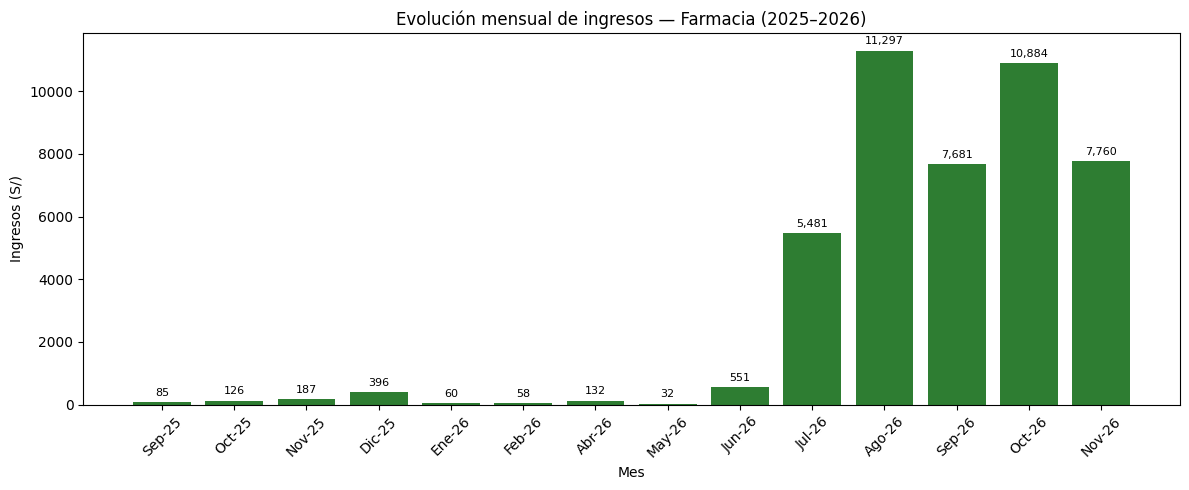

In [0]:
import matplotlib.pyplot as plt
from pyspark.sql import functions as F

orden_meses = ["enero","febrero","marzo","abril","mayo","junio","julio","agosto","septiembre","octubre","noviembre","diciembre"]

evol = (dfFactFarma.groupBy("Año", "Mes")
        .agg(F.sum("Suma_TOTAL_PAGO").alias("ingresos"), F.count("*").alias("pagos"))
        .toPandas())
evol["orden"] = evol["Año"] * 12 + evol["Mes"].map(orden_meses.index)
evol = evol.sort_values("orden")
evol["etiqueta"] = evol["Mes"].str[:3].str.capitalize() + "-" + evol["Año"].astype(str).str[-2:]

plt.figure(figsize=(12, 5))
plt.bar(evol["etiqueta"], evol["ingresos"], color="#2e7d32")
plt.title("Evolución mensual de ingresos — Farmacia (2025–2026)")
plt.xlabel("Mes")
plt.ylabel("Ingresos (S/)")
plt.xticks(rotation=45)
for i, v in enumerate(evol["ingresos"]):
    plt.text(i, v + 200, f"{v:,.0f}", ha="center", fontsize=8)
plt.tight_layout()
plt.show()

**Qué muestra:** el ingreso de cada año-mes en orden cronológico. Se aprecia que 2025 y el primer semestre de 2026 son anecdóticos (barrías casi invisibles) y que el negocio real nace en **julio 2026**, con un pico en **agosto (S/ 11,297)**, un repunte en octubre (S/ 10,884) y un noviembre aún abierto. **Cómo usarlo:** identifica la estacionalidad y el mes de arranque; sirve como línea base para proyectar diciembre.

### 3.2 Top 10 medicamentos por ingresos

Barras horizontales con los 10 medicamentos que más ingresos generan (y sus unidades), para detectar los productos que sostienen la caja.

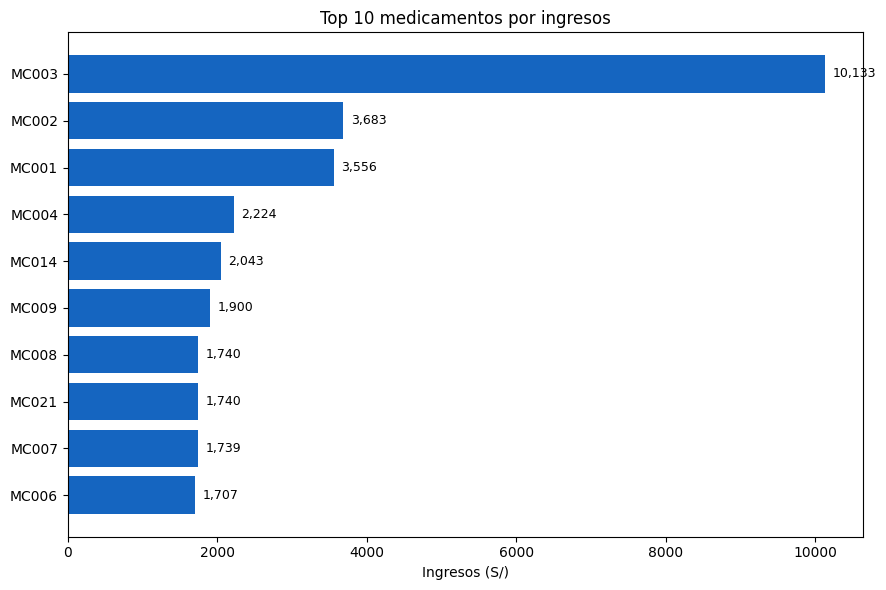

ID_MEDICAMENTO,ingresos,unidades,pagos
MC003,10133,1614,64
MC002,3683,908,77
MC001,3556,1311,93
MC004,2224,241,35
MC014,2043,240,37
MC009,1900,810,27
MC008,1740,810,19
MC021,1740,840,19
MC007,1739,546,37
MC006,1707,670,35


In [0]:
top_med = (dfFactFarma.groupBy("ID_MEDICAMENTO")
           .agg(F.sum("Suma_TOTAL_PAGO").alias("ingresos"), F.sum("SUMA_CANTIDAD").alias("unidades"), F.count("*").alias("pagos"))
           .orderBy(F.desc("ingresos"))
           .limit(10)
           .toPandas())

plt.figure(figsize=(9, 6))
plt.barh(top_med["ID_MEDICAMENTO"][::-1], top_med["ingresos"][::-1], color="#1565c0")
plt.title("Top 10 medicamentos por ingresos")
plt.xlabel("Ingresos (S/)")
for i, v in enumerate(top_med["ingresos"][::-1]):
    plt.text(v + 100, i, f"{v:,.0f}", va="center", fontsize=9)
plt.tight_layout()
plt.show()

display(top_med)

**Qué muestra:** la concentración de ingresos por producto. **MC003 domina con S/ 10,133 (22.7% de todos los ingresos farmacia)**, el doble del segundo (MC002, S/ 3,683). Nota la diferencia de patrones: MC001 vendió en 93 pagos (muchos clientes, ticket chico), mientras MC003 logró S/ 10,133 en 64 pagos (ticket grande: S/ 158 de media). **Cómo usarlo:** protege el stock de MC003/MC002/MC001 — un desabastecimiento de MC003 golpearía casi un cuarto de la caja.

### 3.3 Métodos de pago

Panel izquierdo: participación de cada método en los **ingresos** (torta). Panel derecho: número de **pagos** por método (barras). Comparar ambos revela si un método se usa para tickets grandes o chicos.

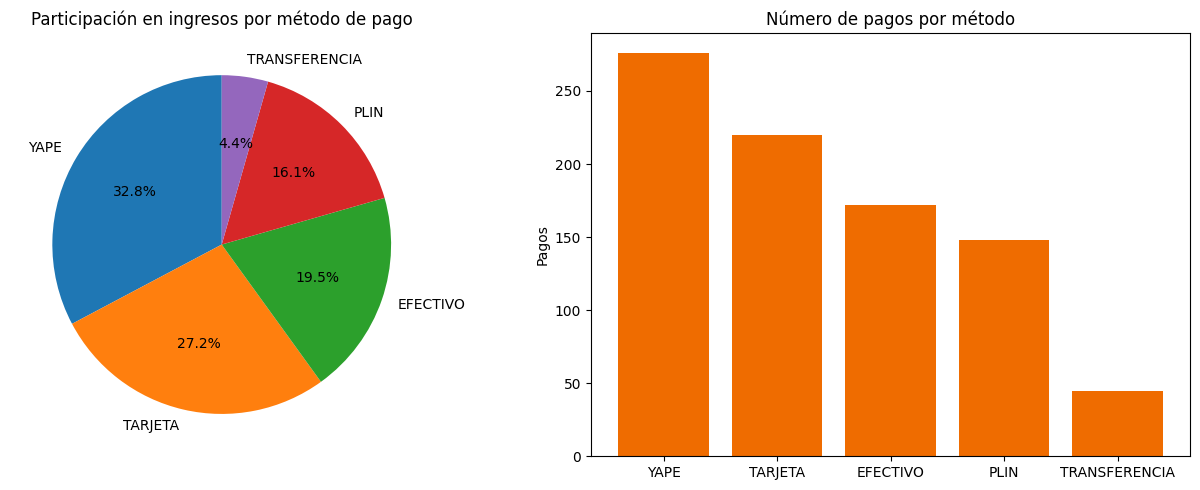

METODO_PAGO,ingresos,pagos
YAPE,14650,276
TARJETA,12171,220
EFECTIVO,8714,172
PLIN,7221,148
TRANSFERENCIA,1974,45


In [0]:
met = (dfFactFarma.groupBy("METODO_PAGO")
       .agg(F.sum("Suma_TOTAL_PAGO").alias("ingresos"), F.count("*").alias("pagos"))
       .orderBy(F.desc("ingresos"))
       .toPandas())

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].pie(met["ingresos"], labels=met["METODO_PAGO"], autopct="%1.1f%%", startangle=90)
ax[0].set_title("Participación en ingresos por método de pago")
ax[1].bar(met["METODO_PAGO"], met["pagos"], color="#ef6c00")
ax[1].set_title("Número de pagos por método")
ax[1].set_ylabel("Pagos")
plt.tight_layout()
plt.show()

display(met)

**Qué muestra:** YAPE lidera ingresos (32.8%) y pagos (276); TARJETA es segundo en ingresos (27.2%) pese a menos pagos (220) → tickets más grandes con tarjeta. EFECTIVO queda tercero (19.5%) y PLIN cuarto (16.1%); TRANSFERENCIA es marginal (4.4%). En conjunto, **los pagos digitales (YAPE+PLIN+TARJETA+TRANSFERENCIA) superan el 80% de los ingresos**: la farmacia es ya un negocio mayoritariamente sin efectivo. **Cómo usarlo:** prioriza la operación de billeteras (QR) y valida comisiones de tarjeta.

### 3.4 Distribución del monto por pago (ticket)

Histograma del monto de cada pago con la media y la mediana marcadas. La media sola engaña cuando la distribución es asimétrica; el histograma muestra la forma real.

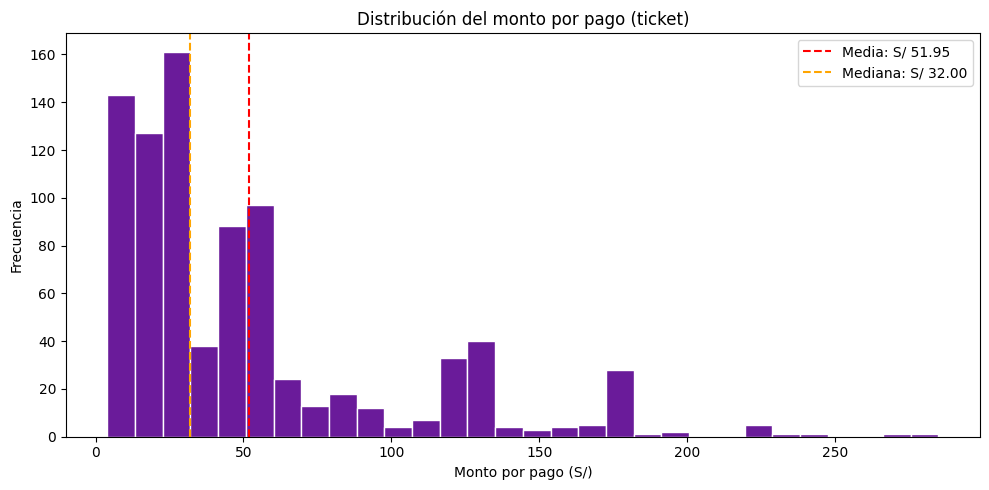

In [0]:
tickets = dfFactFarma.select("Suma_TOTAL_PAGO").toPandas()

plt.figure(figsize=(10, 5))
plt.hist(tickets["Suma_TOTAL_PAGO"], bins=30, color="#6a1b9a", edgecolor="white")
plt.axvline(tickets["Suma_TOTAL_PAGO"].mean(), color="red", linestyle="--",
            label=f"Media: S/ {tickets['Suma_TOTAL_PAGO'].mean():.2f}")
plt.axvline(tickets["Suma_TOTAL_PAGO"].median(), color="orange", linestyle="--",
            label=f"Mediana: S/ {tickets['Suma_TOTAL_PAGO'].median():.2f}")
plt.title("Distribución del monto por pago (ticket)")
plt.xlabel("Monto por pago (S/)")
plt.ylabel("Frecuencia")
plt.legend()
plt.tight_layout()
plt.show()

**Qué muestra:** la distribución está **sesgada a la derecha**: la mayoría de pagos son chicos (la mediana queda por debajo de la media), pero una cola larga de compras grandes (hasta S/ 285) arrastra la media hacia arriba. **Cómo usarlo:** para reportes de "ticket típico" conviene citar la mediana, no la media; los pagos grandes (60 unidades de MC003, MC026, etc.) son los que explican la cola.

### 3.5 Ticket por método de pago

Boxplot del monto por pago para cada método de pago: compara la mediana, el rango y los valores atípicos entre métodos.

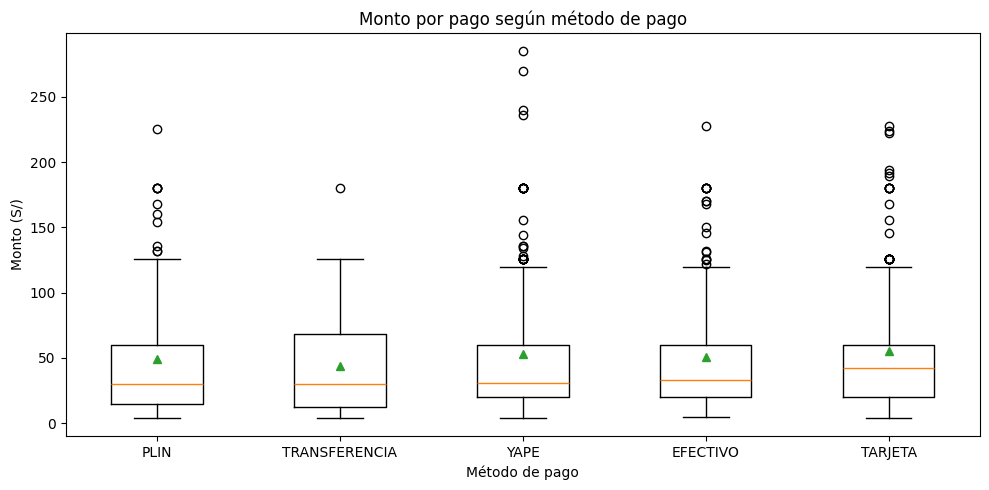

In [0]:
box = dfFactFarma.select("METODO_PAGO", "Suma_TOTAL_PAGO").toPandas()
orden = box.groupby("METODO_PAGO")["Suma_TOTAL_PAGO"].median().sort_values().index.tolist()
data = [box.loc[box["METODO_PAGO"] == m, "Suma_TOTAL_PAGO"] for m in orden]

plt.figure(figsize=(10, 5))
plt.boxplot(data, showmeans=True)
plt.xticks(range(1, len(orden) + 1), orden)
plt.title("Monto por pago según método de pago")
plt.xlabel("Método de pago")
plt.ylabel("Monto (S/)")
plt.tight_layout()
plt.show()

**Qué muestra:** la caja (entre el percentil 25% y 75% de los pagos) y la línea central (mediana) de cada método. **TARJETA tiene la mediana de ticket más alta (S/ 42, media S/ 55.3)** — por eso pesa más en ingresos (27.2%) que en número de pagos — seguida de EFECTIVO (mediana S/ 33). YAPE (S/ 31), TRANSFERENCIA y PLIN (S/ 30) agrupan pagos chicos pero muy numerosos: funcionan por volumen de transacciones, no por monto. Los puntos por encima de los bigotes son compras grandes (outliers), presentes en todos los métodos. **Cómo usarlo:** el perfil de ticket difiere por método; conviene diferenciar la estrategia (promociones QR para volumen, beneficios de tarjeta para tickets grandes).

## 4. Conclusiones

1. **Calidad de datos:** tabla sana (sin nulos, sin duplicados, sin ceros), con la salvedad de que `TOTAL_PAGO` no siempre es igual a `PRECIO×CANTIDAD` (14.5% de filas); se usó `Suma_TOTAL_PAGO` como fuente autoritativa de ingresos.
2. **Negocio reciente:** la farmacia opera en serio desde **julio 2026**; jul–nov 2026 concentra el ~96% de los ingresos (S/ 43,103 de S/ 44,730).
3. **KPIs:** S/ 44,730 en ingresos, 12,737 unidades, 861 pagos, ticket promedio S/ 51.95, 776 pacientes y 35 medicamentos vendidos por 40 farmacéuticos.
4. **Concentración:** MC003 solo aporta el **22.7%** de la caja — dependencia alta de un único producto.
5. **Digitalización:** YAPE (32.8%) + PLIN (16.1%) = 48.9% por billeteras; con TARJETA, más del 80% de los ingresos son pagos sin efectivo.

In [0]:
dfFactCita.write.saveAsTable("big_data.tb_fact_cita")

# Análisis de ventas — Citas médicas (`dfFactCita`)

Análisis exploratorio (EDA), indicadores clave (KPIs) y visualizaciones de las ventas por citas médicas de la clínica, a partir de `big_data.tb_fact_cita`. Cada sección incluye una explicación de qué muestra y cómo interpretarla.

## 1. EDA — Exploración inicial

Revisamos la **estructura** del DataFrame: filas, columnas y tipos. En esta tabla los montos **sí** llegan como texto (con el prefijo "S/ "), así que el primer paso del análisis será limpiarlos; conviene confirmarlo mirando el esquema antes de sumar nada.

In [0]:
print(f"Filas: {dfFactCita.count()} | Columnas: {len(dfFactCita.columns)}")
dfFactCita.printSchema()

Filas: 865 | Columnas: 13
root
 |-- ID_PAGO: string (nullable = true)
 |-- ID_PACIENTE: string (nullable = true)
 |-- ID_MEDICO: string (nullable = true)
 |-- Suma_TOTAL_CITAS: integer (nullable = true)
 |-- NOMBRE_SEGURO: string (nullable = true)
 |-- METODO_PAGO: string (nullable = true)
 |-- Año: integer (nullable = true)
 |-- Trimestre: string (nullable = true)
 |-- Mes: string (nullable = true)
 |-- Día: integer (nullable = true)
 |-- Suma_MONTO: string (nullable = true)
 |-- Suma_DESCUENTO: integer (nullable = true)
 |-- Suma_PAGO_FINAL: string (nullable = true)



**Qué vemos:** 865 filas y 13 columnas. Cada fila es **un pago** (`ID_PAGO` es único). A diferencia de la tabla de farmacia, aquí `Suma_MONTO` y `Suma_PAGO_FINAL` son de tipo **`string`** (traen el prefijo "S/ ") y no se pueden sumar directamente. Además hay `NOMBRE_SEGURO` (8 valores: 3 sin descuento —NINGUNO, SIS, ESSALUD— y 5 EPS privadas) y `Suma_DESCUENTO`, que es un **porcentaje** (0–20), no un monto.

### 1.1 Limpieza y preparación

Creamos `dfCita` a partir de `dfFactCita` con tres correcciones: montos de texto → `double` (quitando "S/ " con `regexp_replace`), y el error tipográfico **YAPEE → YAPE** (1 pago). Así el resto del análisis trabaja con columnas numéricas limpias.

In [0]:
from pyspark.sql import functions as F

dfCita = (dfFactCita
    .withColumn("MONTO", F.regexp_replace("Suma_MONTO", "[^0-9.]", "").cast("double"))
    .withColumn("PAGO_NETO", F.regexp_replace("Suma_PAGO_FINAL", "[^0-9.]", "").cast("double"))
    .withColumn("METODO_PAGO_LIMPIO", F.when(F.col("METODO_PAGO") == "YAPEE", "YAPE").otherwise(F.col("METODO_PAGO"))))

display(dfCita.select("Suma_MONTO", "MONTO", "Suma_PAGO_FINAL", "PAGO_NETO", "METODO_PAGO", "METODO_PAGO_LIMPIO").limit(10))

Suma_MONTO,MONTO,Suma_PAGO_FINAL,PAGO_NETO,METODO_PAGO,METODO_PAGO_LIMPIO
S/ 50,50.0,S/ 50,50.0,YAPE,YAPE
S/ 60,60.0,S/ 60,60.0,EFECTIVO,EFECTIVO
S/ 45,45.0,S/ 45,45.0,TARJETA,TARJETA
S/ 55,55.0,S/ 46.75,46.75,YAPE,YAPE
S/ 40,40.0,S/ 34,34.0,EFECTIVO,EFECTIVO
S/ 70,70.0,S/ 56,56.0,YAPE,YAPE
S/ 50,50.0,S/ 40,40.0,TARJETA,TARJETA
S/ 55,55.0,S/ 44,44.0,EFECTIVO,EFECTIVO
S/ 60,60.0,S/ 60,60.0,YAPE,YAPE
S/ 65,65.0,S/ 65,65.0,TARJETA,TARJETA


**Qué vemos:** la columna original `Suma_MONTO` ("S/ 50") queda convertida en `MONTO` (50.0), y `Suma_PAGO_FINAL` en `PAGO_NETO`. `MONTO` es la tarifa bruta de la cita y `PAGO_NETO` lo que efectivamente pagó el paciente después del descuento del seguro. El único pago con "YAPEE" queda normalizado a "YAPE" para no fragmentar la categoría.

### 1.2 Calidad de datos

Validamos: nulos, duplicados, ceros, rango del descuento y la consistencia aritmética `PAGO_NETO ≈ MONTO × (1 − DESCUENTO/100)`.

In [0]:
calidad_cita = dfCita.agg(
    F.sum(F.col("ID_PAGO").isNull().cast("int")).alias("nulos_id_pago"),
    F.countDistinct("ID_PAGO").alias("pagos_unicos"),
    F.sum((F.col("Suma_TOTAL_CITAS") == 0).cast("int")).alias("citas_en_cero"),
    F.sum((F.col("MONTO") == 0).cast("int")).alias("montos_en_cero"),
    F.sum((F.col("METODO_PAGO") == "YAPEE").cast("int")).alias("typo_yapee"),
    F.min("Suma_DESCUENTO").alias("desc_min"),
    F.max("Suma_DESCUENTO").alias("desc_max"),
    F.round(F.avg("Suma_DESCUENTO"), 2).alias("desc_prom"),
    F.sum((F.abs(F.col("PAGO_NETO") - F.col("MONTO") * (1 - F.col("Suma_DESCUENTO")/100)) > 0.01).cast("int")).alias("filas_inconsistentes")
)
display(calidad_cita)
print(f"Filas totales: {dfCita.count()}")

nulos_id_pago,pagos_unicos,citas_en_cero,montos_en_cero,typo_yapee,desc_min,desc_max,desc_prom,filas_inconsistentes
0,865,0,0,1,0,20,6.77,1


Filas totales: 865


**Qué vemos:** sin nulos, sin filas en cero y `pagos_unicos` = filas (no hay duplicados). El descuento va de **0% a 20%** con promedio simple 6.77%. La aritmética cuadra casi perfecta: **solo 1 de 865 filas** no cumple `PAGO_NETO = MONTO × (1 − desc/100)` — mucho mejor que la tabla de farmacia (125/861). Aun así, usamos `PAGO_NETO` como monto autoritativo.

### 1.3 Estadísticas descriptivas

In [0]:
display(dfCita.agg(
    F.round(F.avg("MONTO"), 2).alias("monto_media"),
    F.round(F.expr("percentile(MONTO, 0.5)"), 2).alias("monto_mediana"),
    F.min("MONTO").alias("monto_min"), F.max("MONTO").alias("monto_max"),
    F.round(F.avg("PAGO_NETO"), 2).alias("pago_medio"),
    F.round(F.expr("percentile(PAGO_NETO, 0.5)"), 2).alias("pago_mediana"),
    F.min("PAGO_NETO").alias("pago_min"), F.max("PAGO_NETO").alias("pago_max"),
    F.round(F.avg("Suma_DESCUENTO"), 2).alias("desc_prom"),
    F.max("Suma_TOTAL_CITAS").alias("max_citas_por_pago"),
    F.round(F.avg("Suma_TOTAL_CITAS"), 2).alias("citas_prom_por_pago")
))

monto_media,monto_mediana,monto_min,monto_max,pago_medio,pago_mediana,pago_min,pago_max,desc_prom,max_citas_por_pago,citas_prom_por_pago
53.05,55.0,40.0,70.0,49.53,48.0,32.0,70.0,6.77,3,1.11


**Qué vemos:**

* `MONTO`: media S/ 53.05, mediana S/ 55, rango 40–70 → **tarifa casi plana** por cita (valores discretos, sin outliers de precio).
* `PAGO_NETO`: media S/ 49.53 — la brecha con la tarifa bruta es exactamente el descuento del seguro.
* Cada pago cubre en promedio **1.11 citas** (máximo 3): casi siempre se paga cita por cita.

### 1.4 Cobertura temporal

Agregamos pagos, citas, bruto y neto por `Año` × `Mes` para ver desde cuándo hay datos reales.

In [0]:
display(dfCita.groupBy("Año", "Mes").agg(
    F.count("*").alias("pagos"),
    F.sum("Suma_TOTAL_CITAS").alias("citas"),
    F.round(F.sum("MONTO"), 2).alias("bruto"),
    F.round(F.sum("PAGO_NETO"), 2).alias("neto")
).orderBy("Año", F.expr("CASE Mes WHEN 'enero' THEN 1 WHEN 'febrero' THEN 2 WHEN 'marzo' THEN 3 WHEN 'abril' THEN 4 WHEN 'mayo' THEN 5 WHEN 'junio' THEN 6 WHEN 'julio' THEN 7 WHEN 'agosto' THEN 8 WHEN 'septiembre' THEN 9 WHEN 'octubre' THEN 10 WHEN 'noviembre' THEN 11 ELSE 12 END")))

Año,Mes,pagos,citas,bruto,neto
2025,septiembre,1,1,50.0,50.0
2025,octubre,4,4,200.0,185.75
2025,noviembre,2,2,120.0,96.0
2025,diciembre,3,3,180.0,169.0
2026,enero,1,1,55.0,55.0
2026,febrero,1,1,50.0,42.5
2026,marzo,2,2,105.0,98.25
2026,abril,1,1,55.0,55.0
2026,mayo,1,1,60.0,48.0
2026,junio,15,18,885.0,826.0


**Qué vemos:**

* **2025 es anecdótico**: 10 pagos entre septiembre y diciembre.
* En **2026** hay pagos aislados de enero a mayo (1–2 por mes) y 15 en junio; el negocio de citas **despega en julio 2026** (131 pagos) y se sostiene: agosto 202 (S/ 9,936 netos), septiembre 160, octubre 192 (S/ 9,565) y noviembre 149 (parcial).
* **Jul–nov 2026 concentra el 96.2% del ingreso neto** — el mismo patrón de arranque que la farmacia.
* Aquí sí existe el mes de marzo (2 pagos), a diferencia de la tabla de farmacia.

## 2. Indicadores clave (KPIs)

Ingresos brutos y netos, descuento total aplicado, citas, pagos, pago promedio, ingreso por cita, pacientes, médicos y participación de billeteras digitales (YAPE + PLIN).

In [0]:
kpis_cita = dfCita.agg(
    F.round(F.sum("MONTO"), 2).alias("ingresos_brutos"),
    F.round(F.sum("PAGO_NETO"), 2).alias("ingresos_netos"),
    F.round(F.sum("MONTO") - F.sum("PAGO_NETO"), 2).alias("descuento_total_soles"),
    F.round((1 - F.sum("PAGO_NETO") / F.sum("MONTO")) * 100, 2).alias("descuento_efectivo_pct"),
    F.sum("Suma_TOTAL_CITAS").alias("citas_totales"),
    F.count("*").alias("pagos"),
    F.round(F.avg("PAGO_NETO"), 2).alias("pago_promedio"),
    F.round(F.sum("PAGO_NETO") / F.sum("Suma_TOTAL_CITAS"), 2).alias("ingreso_por_cita"),
    F.countDistinct("ID_PACIENTE").alias("pacientes"),
    F.countDistinct("ID_MEDICO").alias("medicos"),
    F.round(100 * F.sum(F.when(F.col("METODO_PAGO_LIMPIO").isin("YAPE", "PLIN"), F.col("PAGO_NETO")).otherwise(F.lit(0))) / F.sum("PAGO_NETO"), 1).alias("pct_billeteras")
)
display(kpis_cita)

ingresos_brutos,ingresos_netos,descuento_total_soles,descuento_efectivo_pct,citas_totales,pagos,pago_promedio,ingreso_por_cita,pacientes,medicos,pct_billeteras
45890.0,42843.5,3046.5,6.64,960,865,49.53,44.63,777,50,50.9


**Qué vemos y qué significa cada KPI:**

| KPI | Valor | Interpretación |
| --- | --- | --- |
| Ingresos brutos | S/ 45,890 | Tarifas completas antes del descuento del seguro. |
| Ingresos netos | S/ 42,843.50 | Lo que realmente pagaron los pacientes. |
| Descuento total | S/ 3,046.50 (6.64%) | Aportado por los seguros privados; NINGUNO/SIS/ESSALUD no descuentan. |
| Citas totales | 960 | Volumen de atenciones facturadas. |
| Pagos | 865 | Cada fila = una transacción (1.11 citas por pago en promedio). |
| Pago promedio | S/ 49.53 | Ticket medio por transacción. |
| Ingreso por cita | S/ 44.63 | Neto entre citas: la métrica más limpia para comparar precios. |
| Pacientes únicos | 777 | Clientes distintos atendidos. |
| Médicos | 50 | Plantilla que factura. |
| Billeteras digitales | 50.9% | YAPE + PLIN ya son la mitad del ingreso neto. |

Comparado con la farmacia (S/ 44,730), las citas generan un ingreso neto similar (S/ 42,843.50) pero con muchas menos transacciones (865 vs 861 son parejas; el ticket aquí es casi igual al de farmacia).

## 3. Visualizaciones

### 3.1 Evolución mensual del ingreso neto

Barra por año-mes en orden cronológico real (meses en español ordenados con lista fija, no alfabéticamente).

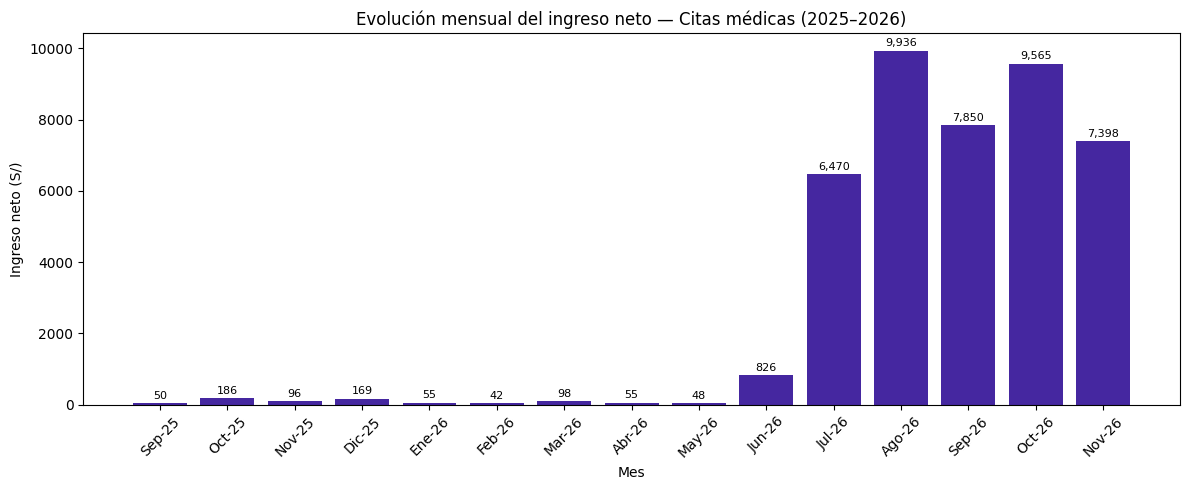

In [0]:
import matplotlib.pyplot as plt

orden_meses = ["enero","febrero","marzo","abril","mayo","junio","julio","agosto","septiembre","octubre","noviembre","diciembre"]

evol_cita = (dfCita.groupBy("Año", "Mes")
             .agg(F.sum("PAGO_NETO").alias("neto"), F.count("*").alias("pagos"))
             .toPandas())
evol_cita["orden"] = evol_cita["Año"] * 12 + evol_cita["Mes"].map(orden_meses.index)
evol_cita = evol_cita.sort_values("orden")
evol_cita["etiqueta"] = evol_cita["Mes"].str[:3].str.capitalize() + "-" + evol_cita["Año"].astype(str).str[-2:]

plt.figure(figsize=(12, 5))
plt.bar(evol_cita["etiqueta"], evol_cita["neto"], color="#4527a0")
plt.title("Evolución mensual del ingreso neto — Citas médicas (2025–2026)")
plt.xlabel("Mes")
plt.ylabel("Ingreso neto (S/)")
plt.xticks(rotation=45)
for i, v in enumerate(evol_cita["neto"]):
    plt.text(i, v + 120, f"{v:,.0f}", ha="center", fontsize=8)
plt.tight_layout()
plt.show()

**Qué muestra:** el ingreso neto por año-mes en orden cronológico. 2025 y el primer semestre de 2026 son anecdóticos; el negocio de citas nace en **julio 2026**, con pico en **agosto (S/ 9,936)**, y octubre casi igual (S/ 9,565). **Cómo usarlo:** línea base para proyectar diciembre y medir la estacionalidad; la forma es casi idéntica a la de la farmacia, confirmando que ambas líneas de negocio arrancaron juntas.

### 3.2 Top 10 médicos por ingreso neto

Barras horizontales con los médicos que más ingreso generan, junto con sus pagos y citas.

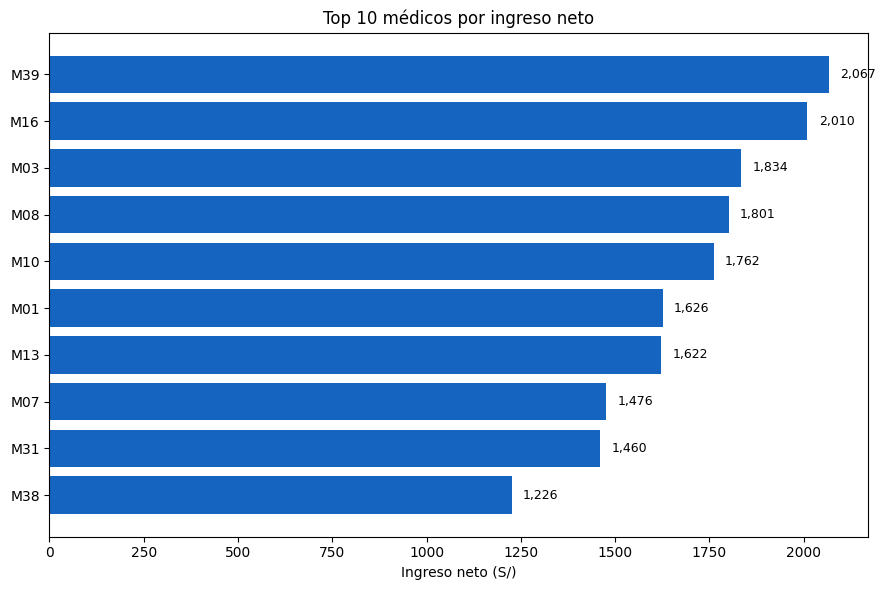

ID_MEDICO,neto,pagos,citas
M39,2067.0,36,39
M16,2010.0,54,60
M03,1833.75,43,48
M08,1801.25,35,39
M10,1761.5,28,29
M01,1626.5,42,45
M13,1622.25,29,31
M07,1476.5,32,39
M31,1460.0,39,42
M38,1226.25,29,32


In [0]:
top_med_cita = (dfCita.groupBy("ID_MEDICO")
                 .agg(F.sum("PAGO_NETO").alias("neto"), F.count("*").alias("pagos"), F.sum("Suma_TOTAL_CITAS").alias("citas"))
                 .orderBy(F.desc("neto"))
                 .limit(10)
                 .toPandas())

plt.figure(figsize=(9, 6))
plt.barh(top_med_cita["ID_MEDICO"][::-1], top_med_cita["neto"][::-1], color="#1565c0")
plt.title("Top 10 médicos por ingreso neto")
plt.xlabel("Ingreso neto (S/)")
for i, v in enumerate(top_med_cita["neto"][::-1]):
    plt.text(v + 30, i, f"{v:,.0f}", va="center", fontsize=9)
plt.tight_layout()
plt.show()

display(top_med_cita)

**Qué muestra:** **M39 lidera con S/ 2,067 en solo 36 pagos**, seguido de M16 (S/ 2,010 en 54 pagos) — M39 factura casi lo mismo con un tercio menos de transacciones (tarifa o caso más complejo). El top 10 (20% de los 50 médicos) concentra el **39.4% del ingreso neto**. **Cómo usarlo:** los médicos del top son el motor de caja; su ausencia (vacaciones, rotación) tendría impacto directo en la facturación.

### 3.3 Seguros médicos

Panel izquierdo: ingreso neto por seguro. Panel derecho: descuento promedio que aplica cada seguro. Comparar ambos muestra qué aseguradoras aportan caja y cuánto "regalan" en descuentos.

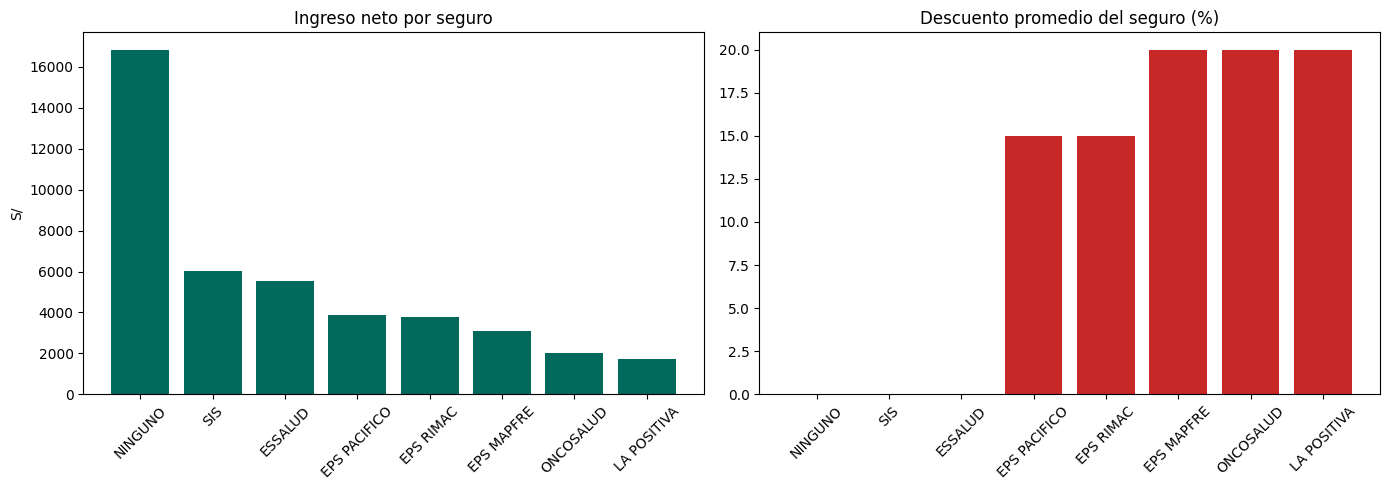

NOMBRE_SEGURO,neto,desc_prom
NINGUNO,16840.0,0.0
SIS,6015.0,0.0
ESSALUD,5515.0,0.0
EPS PACIFICO,3876.0,15.0
EPS RIMAC,3769.5,15.0
EPS MAPFRE,3092.0,20.0
ONCOSALUD,2016.0,20.0
LA POSITIVA,1720.0,20.0


In [0]:
seg = (dfCita.groupBy("NOMBRE_SEGURO")
       .agg(F.sum("PAGO_NETO").alias("neto"), F.round(F.avg("Suma_DESCUENTO"), 1).alias("desc_prom"))
       .orderBy(F.desc("neto"))
       .toPandas())

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].bar(seg["NOMBRE_SEGURO"], seg["neto"], color="#00695c")
ax[0].set_title("Ingreso neto por seguro")
ax[0].set_ylabel("S/")
ax[0].tick_params(axis="x", rotation=45)
ax[1].bar(seg["NOMBRE_SEGURO"], seg["desc_prom"], color="#c62828")
ax[1].set_title("Descuento promedio del seguro (%)")
ax[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

display(seg)

**Qué muestra:** los **pacientes particulares (NINGUNO) son el mayor origen de caja: 39.3% del ingreso neto**, por encima de cualquier aseguradora; les siguen SIS y ESSALUD. El panel derecho explica el patrón de descuentos: NINGUNO, SIS y ESSALUD **no descuentan nada** (0%), mientras las EPS privadas descuentan 15% (PACIFICO, RIMAC) y 20% (MAPFRE, ONCOSALUD, LA POSITIVA). En total, el **66.2% del ingreso neto se paga sin descuento** — los seguros privados solo explican el 6.64% de la facturación. **Cómo usarlo:** la clínica es menos dependiente de las aseguradoras de lo que parece; negociar tarifas con EPS privadas afecta solo un tercio de la caja.

### 3.4 Métodos de pago

Panel izquierdo: participación en el ingreso neto (torta). Panel derecho: número de pagos (barras). Se usa `METODO_PAGO_LIMPIO` (YAPEE corregido a YAPE).

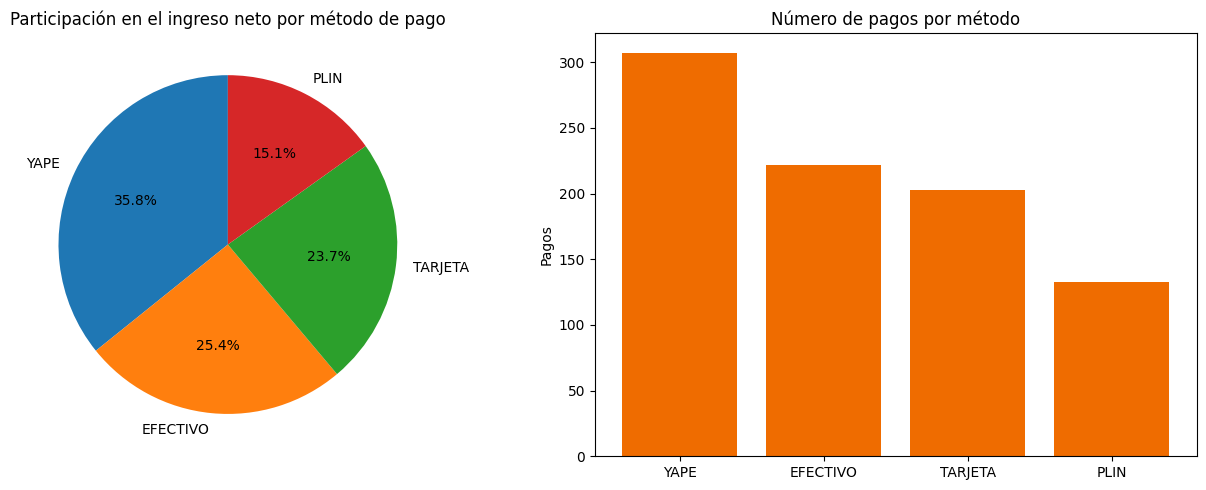

METODO_PAGO_LIMPIO,neto,pagos
YAPE,15328.75,307
EFECTIVO,10866.75,222
TARJETA,10170.0,203
PLIN,6478.0,133


In [0]:
met_c = (dfCita.groupBy("METODO_PAGO_LIMPIO")
         .agg(F.sum("PAGO_NETO").alias("neto"), F.count("*").alias("pagos"))
         .orderBy(F.desc("neto"))
         .toPandas())

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].pie(met_c["neto"], labels=met_c["METODO_PAGO_LIMPIO"], autopct="%1.1f%%", startangle=90)
ax[0].set_title("Participación en el ingreso neto por método de pago")
ax[1].bar(met_c["METODO_PAGO_LIMPIO"], met_c["pagos"], color="#ef6c00")
ax[1].set_title("Número de pagos por método")
ax[1].set_ylabel("Pagos")
plt.tight_layout()
plt.show()

display(met_c)

**Qué muestra:** **YAPE lidera con 35.8% del ingreso neto** (307 pagos) y PLIN agrega 15.1% — las billeteras suman **50.9%**. A diferencia de la farmacia, aquí **EFECTIVO es segundo (25.4%)**: en el consultorio todavía hay una cuarta parte de pagos en cash (aquí no existe TRANSFERENCIA). TARJETA aporta 23.7%. **Cómo usarlo:** aunque las billeteras dominan, el efectivo sigue siendo relevante solo en citas — vale mantener cambio/caja en recepción, algo innecesario en farmacia.

### 3.5 Distribución del pago neto (ticket)

Histograma del monto neto por pago con la media y la mediana marcadas.

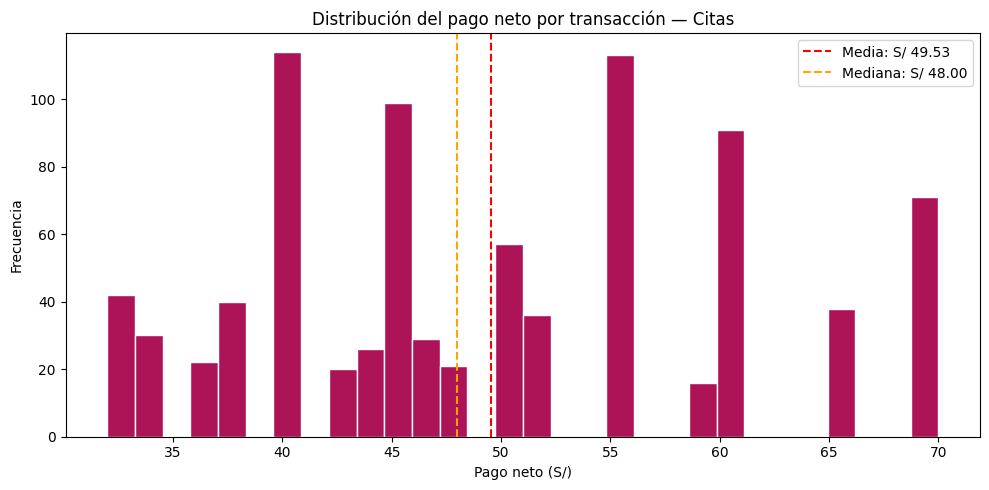

In [0]:
pagos_hist = dfCita.select("PAGO_NETO").toPandas()

plt.figure(figsize=(10, 5))
plt.hist(pagos_hist["PAGO_NETO"], bins=30, color="#ad1457", edgecolor="white")
plt.axvline(pagos_hist["PAGO_NETO"].mean(), color="red", linestyle="--",
            label=f"Media: S/ {pagos_hist['PAGO_NETO'].mean():.2f}")
plt.axvline(pagos_hist["PAGO_NETO"].median(), color="orange", linestyle="--",
            label=f"Mediana: S/ {pagos_hist['PAGO_NETO'].median():.2f}")
plt.title("Distribución del pago neto por transacción — Citas")
plt.xlabel("Pago neto (S/)")
plt.ylabel("Frecuencia")
plt.legend()
plt.tight_layout()
plt.show()

**Qué muestra:** a diferencia de la farmacia (cola larga hasta S/ 285), aquí la tarifa es **plana y acotada** (S/ 40–70 brutos), y los descuentos fijos de 0%/15%/20% generan **bandas discretas** de pago en lugar de una curva continua — por eso el histograma muestra picos separados en lugar de una cola. Media (≈ S/ 49.5) y mediana (S/ 48) están casi pegadas: sin outliers que distorsionen el ticket típico. **Cómo usarlo:** el "ticket típico" de citas es estable y predecible (≈ S/ 48–50); cualquier desviación grande delataría un cambio de tarifa o un error de registro.

## 4. Conclusiones — Citas médicas

1. **Calidad de datos:** limpia tras la corrección de tipos (montos "S/ " → double) y del typo YAPEE; aritmética casi perfecta (solo 1/865 filas inconsistente) y sin nulos, duplicados ni ceros.
2. **Negocio reciente:** como la farmacia, las citas despegan en **julio 2026**; jul–nov concentra el 96.2% del neto (S/ 41,218 de S/ 42,843.50).
3. **KPIs:** bruto S/ 45,890 → neto S/ 42,843.50 (descuento de seguros S/ 3,046.50, 6.64%); 960 citas en 865 pagos; pago promedio S/ 49.53; ingreso por cita S/ 44.63; 777 pacientes y 50 médicos.
4. **Concentración:** el top 10 de médicos (20% de la plantilla) genera el 39.4% del ingreso; M39 y M16 lideran con ~S/ 2,000 cada uno.
5. **Seguros:** los particulares (NINGUNO) son el mayor origen de caja (39.3%); el 66.2% del neto se paga sin descuento — los seguros privados solo explican el 6.64%.
6. **Pagos:** YAPE 35.8% + PLIN 15.1% = 50.9% por billeteras; EFECTIVO 25.4% (mucho más que en farmacia) y TARJETA 23.7%.